In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

base = "/content/drive/MyDrive/anon/pidgindataset2026October/"

df = pd.read_csv(base+"metadata_version2.0.csv")

Mounted at /content/drive


In [2]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,signal_to_noise_ratio,silence_ratio,audio,file_exists,text,reference,sample_id,pidgin_word_count,english_word_count,length_ratio
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","['exercise', 'everytime', 'after two day', 'no...",19.04,16000.0,1.0,2.678378,54.947548,0.319377,/content/drive/MyDrive/Brock_University/pidgin...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,51,34,1.500000
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","['daughter', 'wake up', 'vomited', 'pain', 'ho...",34.48,16000.0,1.0,2.580879,53.953575,0.334655,/content/drive/MyDrive/Brock_University/pidgin...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,89,136,0.654412
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","['reasons', 'removed', 'important part of the ...",21.97,16000.0,1.0,2.321869,57.647476,0.335672,/content/drive/MyDrive/Brock_University/pidgin...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,51,56,0.910714
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","['thirty one years woman', 'not', 'head injury...",34.61,16000.0,1.0,2.571562,49.890247,0.308394,/content/drive/MyDrive/Brock_University/pidgin...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,89,94,0.946809
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","['forty five years old man', 'platelet count',...",42.63,16000.0,1.0,2.040783,50.834831,0.307166,/content/drive/MyDrive/Brock_University/pidgin...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,87,81,1.074074


In [ ]:
df.drop(columns=["topic_id", "topic_confidence"], inplace=True)

In [ ]:
df.rename(columns={"medical_terms_clean": "medical_terms"}, inplace=True)

In [4]:
import ast
import pandas as pd

# ensure list format
def ensure_list(x):
    if isinstance(x, list):
        return x
    if pd.isna(x):
        return []
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except:
            return []
    return []

df["medical_terms_pidgen"] = df["medical_terms_pidgen"].apply(ensure_list)

# extend stopword list
extra_remove = {
    "daughter", "boyfriend"
}

def remove_unwanted_terms(terms):
    if not isinstance(terms, list):
        return []
    return [t for t in terms if t not in extra_remove]

df["medical_terms_pidgen"] = df["medical_terms_pidgen"].apply(remove_unwanted_terms)

In [5]:
df["medical_terms_text"] = df["medical_terms_pidgen"].apply(
    lambda terms: " ".join(terms) if isinstance(terms, list) else ""
)

In [6]:
from transformers import pipeline
from collections import Counter

ner = pipeline(
    "ner",
    model="d4data/biomedical-ner-all",
    aggregation_strategy="simple",
    device=0
)

def classify_medical_topic(text):
    if not isinstance(text, str) or len(text.strip()) == 0:
        return "Unknown"

    results = ner(text)

    labels = [r["entity_group"] for r in results]

    if len(labels) == 0:
        return "General"

    label_counts = Counter(labels)
    return label_counts.most_common(1)[0][0]

df["medical_topic_label"] = df["medical_terms_text"].apply(classify_medical_topic)

config.json:   0%|          | 0.00/5.00k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  266MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


In [ ]:
df.drop(columns=["medical_topic_id", "medical_topic_confidence"], inplace=True)

In [7]:
label_map = {
    "Sign_symptom": "Symptom",
    "Severity": "Symptom",
    "Clinical_event": "Symptom",

    "Disease_disorder": "Disease",

    "Medication": "Medication",
    "Dosage": "Medication",
    "Administration": "Medication",

    "Diagnostic_procedure": "Procedure",
    "Therapeutic_procedure": "Procedure",

    "Biological_structure": "Anatomy",
    "Nonbiological_location": "Anatomy",

    "Lab_value": "Lab",
    "Quantitative_concept": "Lab",

    "Detailed_description": "Descriptor",
    "Qualitative_concept": "Descriptor",
    "Texture": "Descriptor",
    "Color": "Descriptor",
    "Shape": "Descriptor",

    "Date": "Temporal",
    "Time": "Temporal",
    "Frequency": "Temporal",

    "Sex": "Demographic",
    "Subject": "Demographic",
    "Occupation": "Demographic",

    "History": "History",
    "Family_history": "History",

    "Activity": "General",
    "Other_event": "General",
    "General": "General",
    "Distance": "General",
    "Coreference": "General",

}

In [8]:
from collections import Counter

def map_to_category(label):
    if label == "Unknown":
        return "General"
    return label_map.get(label, "General")

def assign_clinical_category(text):
    if not isinstance(text, str) or len(text.strip()) == 0:
        return "General"

    results = ner(text)

    labels = [map_to_category(r["entity_group"]) for r in results]

    if len(labels) == 0:
        return "General"

    return Counter(labels).most_common(1)[0][0]

df["clinical_category"] = df["medical_terms_text"].apply(assign_clinical_category)

In [9]:
topic_dist = (
    df["clinical_category"]
    .value_counts()
    .reset_index()
)

topic_dist.columns = ["category", "count"]

topic_dist["percentage"] = (
    topic_dist["count"] / len(df) * 100
).round(2)

print(topic_dist["category"].unique())

top7 = topic_dist.head(11)
top7

['Symptom' 'Procedure' 'Anatomy' 'Medication' 'Descriptor' 'General'
 'Disease' 'Lab' 'Temporal' 'Demographic' 'History']


,category,count,percentage
0,Symptom,2271,22.23
1,Procedure,1850,18.11
2,Anatomy,1416,13.86
3,Medication,1307,12.79
4,Descriptor,1098,10.75
5,General,841,8.23
6,Disease,487,4.77
7,Lab,462,4.52
8,Temporal,291,2.85
9,Demographic,121,1.18


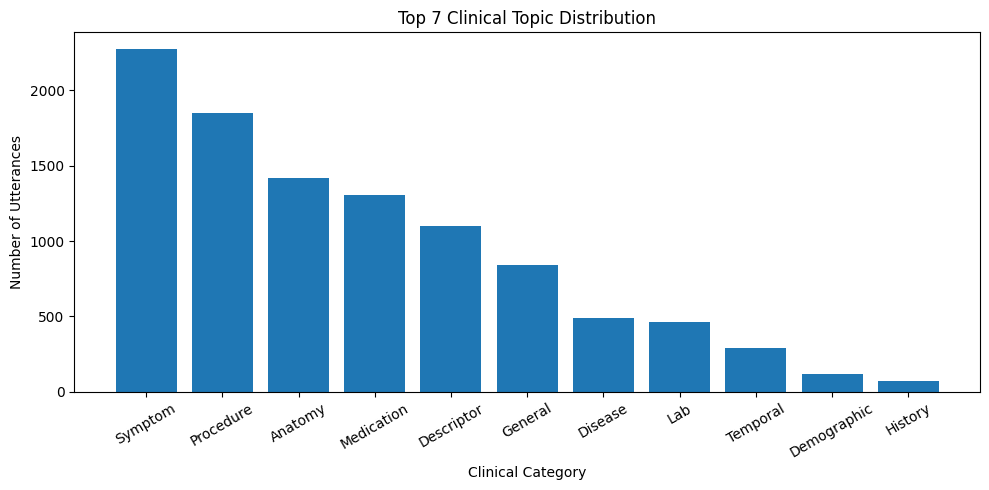

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(
    top7["category"],
    top7["count"]
)

plt.title("Top 7 Clinical Topic Distribution")
plt.xlabel("Clinical Category")
plt.ylabel("Number of Utterances")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [11]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,...,file_exists,text,reference,sample_id,pidgin_word_count,english_word_count,length_ratio,medical_terms_text,medical_topic_label,clinical_category
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","[exercise, everytime, after two day, normally,...",19.04,16000.0,1.0,2.678378,...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,51,34,1.500000,exercise everytime after two day normally one ...,Frequency,Temporal
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","[wake up, vomited, pain, hot, paracetamol, sle...",34.48,16000.0,1.0,2.580879,...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,89,136,0.654412,wake up vomited pain hot paracetamol sleep two...,Sign_symptom,Symptom
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","[reasons, removed, important part of the body,...",21.97,16000.0,1.0,2.321869,...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,51,56,0.910714,reasons removed important part of the body exa...,Detailed_description,Descriptor
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","[thirty one years woman, not, head injury, inj...",34.61,16000.0,1.0,2.571562,...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,89,94,0.946809,thirty one years woman not head injury injury ...,Biological_structure,Anatomy
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","[forty five years old man, platelet count, thi...",42.63,16000.0,1.0,2.040783,...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,87,81,1.074074,forty five years old man platelet count thirty...,Medication,Medication


In [12]:
df["medical_topic_label"].unique()

array(['Frequency', 'Sign_symptom', 'Detailed_description',
       'Biological_structure', 'Medication', 'Lab_value',
       'Disease_disorder', 'Dosage', 'Diagnostic_procedure',
       'Therapeutic_procedure', 'Duration', 'Nonbiological_location',
       'History', 'Date', 'Unknown', 'Age', 'Subject', 'Time', 'Activity',
       'Clinical_event', 'Family_history', 'Coreference', 'Shape',
       'Severity', 'Sex', 'Color', 'General', 'Administration', 'Texture',
       'Other_event', 'Qualitative_concept', 'Quantitative_concept',
       'Occupation', 'Distance', 'Personal_background'], dtype=object)

In [14]:
from collections import Counter

# Flatten list of lists
all_terms = [term for terms in df["medical_terms_pidgen"] for term in terms]

# Count frequencies
term_counts = Counter(all_terms)

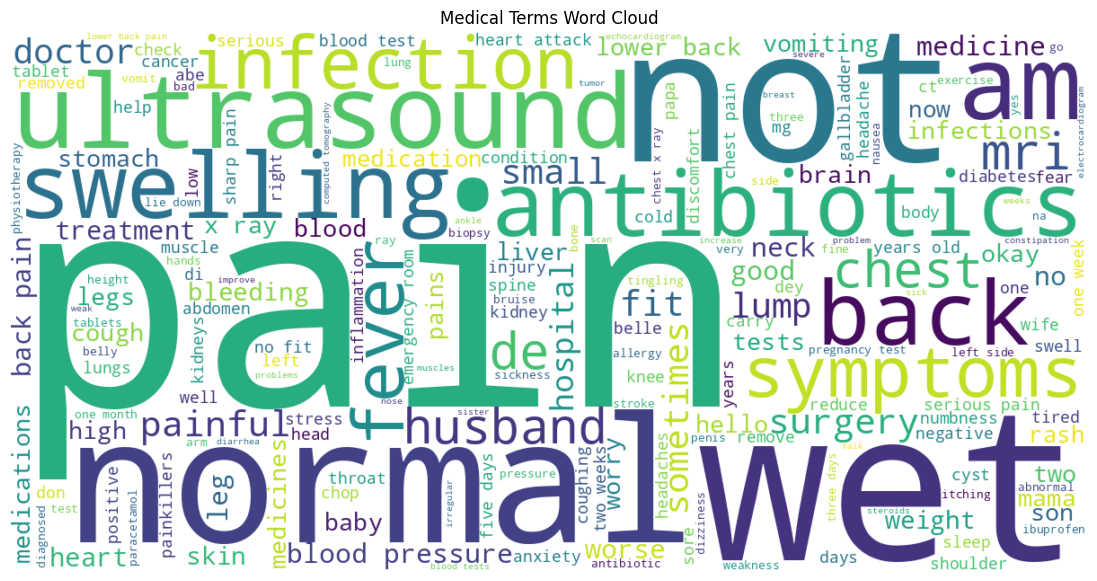

In [21]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    collocations=False,   # important: avoid combining words
    max_words=200
).generate_from_frequencies(term_counts)

plt.figure(figsize=(14,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Medical Terms Word Cloud")
plt.show()

In [17]:
df.head()

,speaker_id,audio_path,pidgin_transcription,english_translation,medical_terms_english,medical_terms_pidgen,audio_length,sample_rate,num_channels,speech_rate,...,file_exists,text,reference,sample_id,pidgin_word_count,english_word_count,length_ratio,medical_terms_text,medical_topic_label,clinical_category
0,Speaker_1,root/audio/Speaker_1/Speaker1-1.wav,e depend on your effort how you take dey do ex...,it all depends on your efforts regarding regul...,"['care', 'knee', 'walk', 'two days', 'one to t...","[exercise, everytime, after two day, normally,...",19.04,16000.0,1.0,2.678378,...,True,e depend on your effort how you take dey do ex...,e depend on your effort how you take dey do ex...,6a840a4ad1fd60283227,51,34,1.500000,exercise everytime after two day normally one ...,Frequency,Temporal
1,Speaker_1,root/audio/Speaker_1/Speaker1-2.wav,my daughter make four years two nights ago she...,my daughter is four years old two nights ago s...,"['daughter', 'four years old', 'vomited', 'sor...","[wake up, vomited, pain, hot, paracetamol, sle...",34.48,16000.0,1.0,2.580879,...,True,my daughter make four years two nights ago she...,my daughter make four years two nights ago she...,fa777d58c8f323da62e2,89,136,0.654412,wake up vomited pain hot paracetamol sleep two...,Sign_symptom,Symptom
2,Speaker_1,root/audio/Speaker_1/Speaker1-3.wav,hi dis na retention cyst e go need excise for ...,hi this is definitely a retention cyst it need...,"['retention cyst', 'mass', 'histopathological ...","[reasons, removed, important part of the body,...",21.97,16000.0,1.0,2.321869,...,True,hi dis na retention cyst e go need excise for ...,hi dis na retention cyst e go need excise for ...,01fceaa9e74b77698df4,51,56,0.910714,reasons removed important part of the body exa...,Detailed_description,Descriptor
3,Speaker_1,root/audio/Speaker_1/Speaker1-4.wav,i be thirty one years woman and i get blod clo...,i am a thirty one year old woman with a blood ...,"['thirty one year old woman', 'head injury', '...","[thirty one years woman, not, head injury, inj...",34.61,16000.0,1.0,2.571562,...,True,i be thirty one years woman and i get blod clo...,i be thirty one years woman and i get blod clo...,3d812380dee30f23b366,89,94,0.946809,thirty one years woman not head injury injury ...,Biological_structure,Anatomy
4,Speaker_1,root/audio/Speaker_1/Speaker1-5.wav,i be forty five years old man my platelet coun...,i am forty five years old male my platelet cou...,"['forty five years old male', 'platelet count'...","[forty five years old man, platelet count, thi...",42.63,16000.0,1.0,2.040783,...,True,i be forty five years old man my platelet coun...,i be forty five years old man my platelet coun...,ac3bdc92665cb5600166,87,81,1.074074,forty five years old man platelet count thirty...,Medication,Medication


In [18]:
df.to_csv(base+"metadata_versionMedicalTopicDistribution.csv", index=False)